In [68]:
import pandas as pd

client = pd.read_csv("telecom/Client.csv")
record = pd.read_csv("telecom/Record.csv")

print(client.shape)
print(record.shape)

print("CLIENT DATASET")
print(client.head())

print("\nRECORD DATASET")
print(record.head())

print("CLIENT INFORMATION")
print(client.info())

print("\nRECORD INFORMATION")
print(record.info())

print("CLIENT MISSING VALUES")
print(client.isnull().sum().sort_values(ascending=False).head(15))

print("\nRECORD MISSING VALUES")
print(record.isnull().sum().sort_values(ascending=False).head(15))

print("CLIENT DUPLICATES:")
print(client["Customer_ID"].duplicated().sum())

print("RECORD DUPLICATES:")
print(record["Customer_ID"].duplicated().sum())

matching_customers = client["Customer_ID"].isin(record["Customer_ID"]).sum()

print("MATCHING CUSTOMERS:", matching_customers)

print("CHURN DISTRIBUTION")
print(record["churn"].value_counts())

print("\nCHURN PERCENTAGES")
print(record["churn"].value_counts(normalize=True) * 100)

print("CLIENT SUMMARY")
print(client.describe())

print("\nRECORD SUMMARY")
print(record.describe())


(100000, 50)
(100000, 51)
CLIENT DATASET
   uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls       totmou  \
0         2         1        U        A        N      1652   4228.00000   
1         1         1        N       EA        N     14654  26400.00000   
2         1         1        Y        C        N      7903  24385.05333   
3         1         1        Y        B        N      1502   3065.00000   
4         1         1        Y        A        N      4485  14028.00000   

    totrev   adjrev    adjmou  ...  forgntvl  ethnic  kid0_2  kid3_5  kid6_10  \
0  1504.62  1453.44   4085.00  ...       0.0       N       U       U        U   
1  2851.68  2833.88  26367.00  ...       0.0       Z       U       U        U   
2  2155.91  1934.47  24303.05  ...       0.0       N       U       Y        U   
3  2000.90  1941.81   3035.00  ...       0.0       U       Y       U        U   
4  2181.12  2166.48  13965.00  ...       0.0       I       U       U        U   

   kid11_15  kid16_17

COMBINED DATASET: (100000, 100)
   uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls       totmou  \
0         2         1        U        A        N      1652   4228.00000   
1         1         1        N       EA        N     14654  26400.00000   
2         1         1        Y        C        N      7903  24385.05333   
3         1         1        Y        B        N      1502   3065.00000   
4         1         1        Y        A        N      4485  14028.00000   

    totrev   adjrev    adjmou  ...  opk_dat_Mean  mou_opkv_Mean  \
0  1504.62  1453.44   4085.00  ...           0.0      55.220000   
1  2851.68  2833.88  26367.00  ...           0.0     169.343333   
2  2155.91  1934.47  24303.05  ...           0.0       0.233333   
3  2000.90  1941.81   3035.00  ...           0.0       5.450000   
4  2181.12  2166.48  13965.00  ...           0.0     218.086667   

   mou_opkd_Mean  drop_blk_Mean  attempt_Mean  complete_Mean  callfwdv_Mean  \
0            0.0       1.333333    

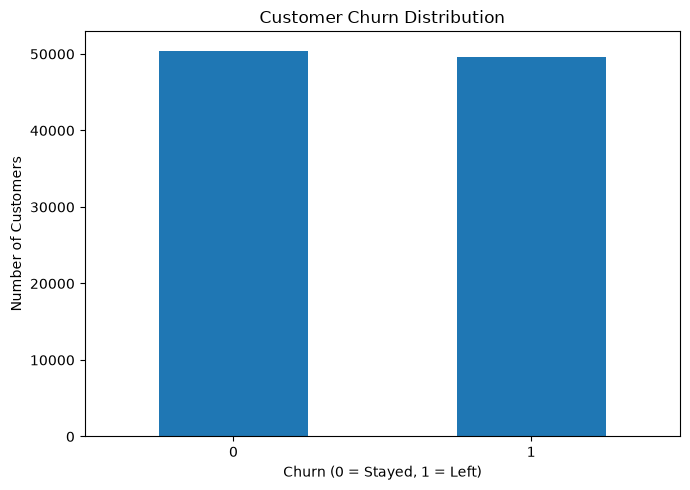

In [69]:
# Combine Client and Record datasets
data = pd.merge(
    client,
    record,
    on="Customer_ID",
    how="inner",
    validate="one_to_one"
)

print("COMBINED DATASET:", data.shape)
print(data.head())

# Compare average values by churn status
columns_to_check = [
    "rev_Mean",
    "mou_Mean",
    "custcare_Mean",
    "drop_vce_Mean",
    "months",
    "eqpdays"
]

churn_comparison = data.groupby("churn")[columns_to_check].mean()

print(churn_comparison)

import matplotlib.pyplot as plt

churn_counts = data["churn"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



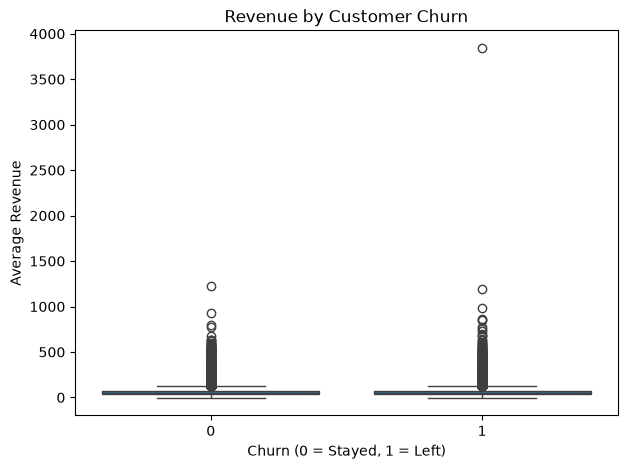

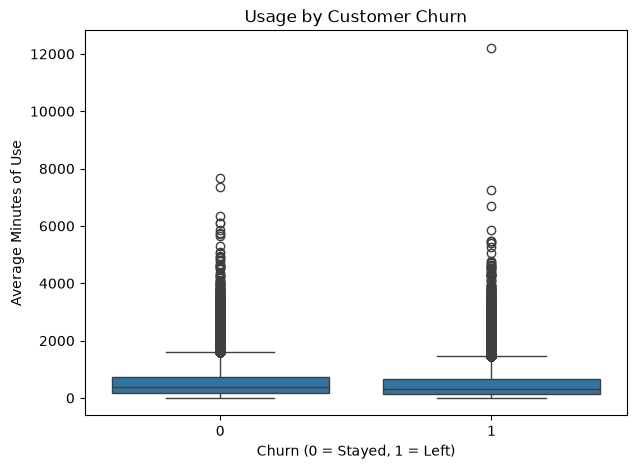

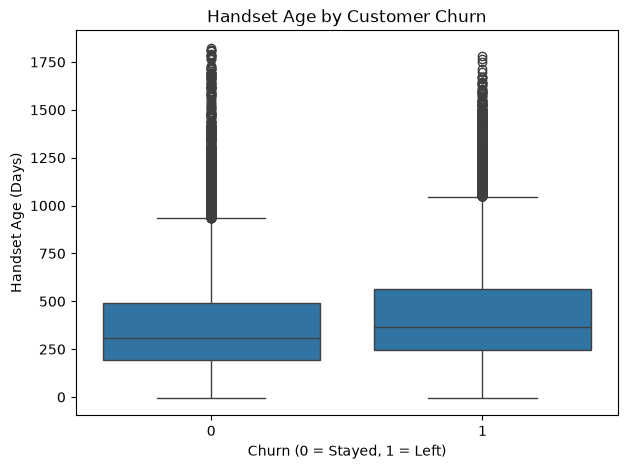

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# Revenue comparison
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="churn", y="rev_Mean")
plt.title("Revenue by Customer Churn")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Average Revenue")
plt.show()

# Usage comparison
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="churn", y="mou_Mean")
plt.title("Usage by Customer Churn")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Average Minutes of Use")
plt.show()

# Handset age comparison
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="churn", y="eqpdays")
plt.title("Handset Age by Customer Churn")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Handset Age (Days)")
plt.show()

Initial exploratory analysis found that 49.562% of customers churned. Customers who churned had lower average usage and slightly lower average revenue, while their handsets were older on average. These patterns suggest potential areas for further investigation in customer retention.

<Figure size 700x500 with 0 Axes>

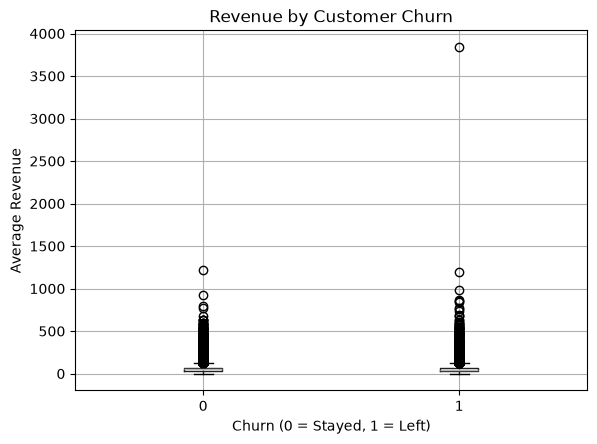

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

data.boxplot(column="rev_Mean", by="churn")

plt.title("Revenue by Customer Churn")
plt.suptitle("")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Average Revenue")

plt.show()

<Figure size 700x500 with 0 Axes>

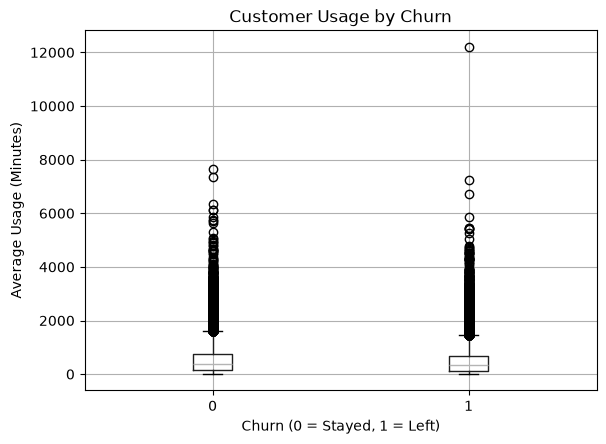

In [72]:
plt.figure(figsize=(7, 5))

data.boxplot(column="mou_Mean", by="churn")

plt.title("Customer Usage by Churn")
plt.suptitle("")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Average Usage (Minutes)")

plt.show()

<Figure size 700x500 with 0 Axes>

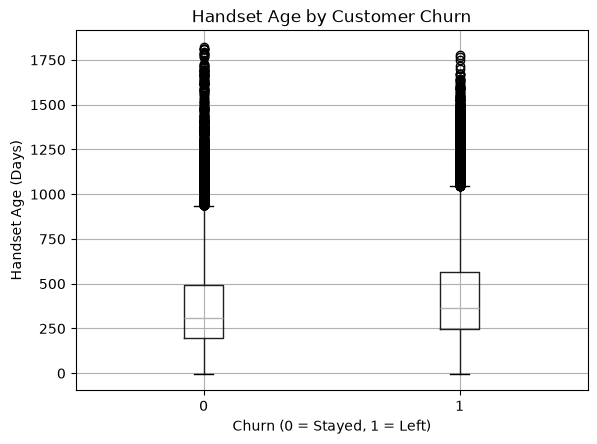

In [73]:
plt.figure(figsize=(7, 5))

data.boxplot(column="eqpdays", by="churn")

plt.title("Handset Age by Customer Churn")
plt.suptitle("")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Handset Age (Days)")

plt.show()

In [74]:
# Select numerical columns
numeric_data = data.select_dtypes(include="number")

# Calculate correlations with churn
churn_correlation = numeric_data.corr()["churn"].drop("churn")

# Sort correlations
churn_correlation = churn_correlation.sort_values(
    ascending=False,
    key=abs
)

print(churn_correlation.head(15))

eqpdays          0.112691
hnd_price       -0.103184
totmrc_Mean     -0.068558
mou_Mean        -0.057027
mou_cvce_Mean   -0.052042
complete_Mean   -0.051740
comp_vce_Mean   -0.051574
avg3mou         -0.049546
mou_opkv_Mean   -0.048896
attempt_Mean    -0.048533
plcd_vce_Mean   -0.048321
peak_vce_Mean   -0.048320
opk_vce_Mean    -0.047873
mou_peav_Mean   -0.047287
mou_rvce_Mean   -0.047148
Name: churn, dtype: float64


Correlation analysis findings

The strongest positive correlation with churn was eqpdays (0.113), suggesting that customers with older handsets tend to have slightly higher churn rates.

The strongest negative correlation was hnd_price (-0.103). However, all the correlations were relatively weak, indicating that no single numerical variable has a strong linear relationship with churn.

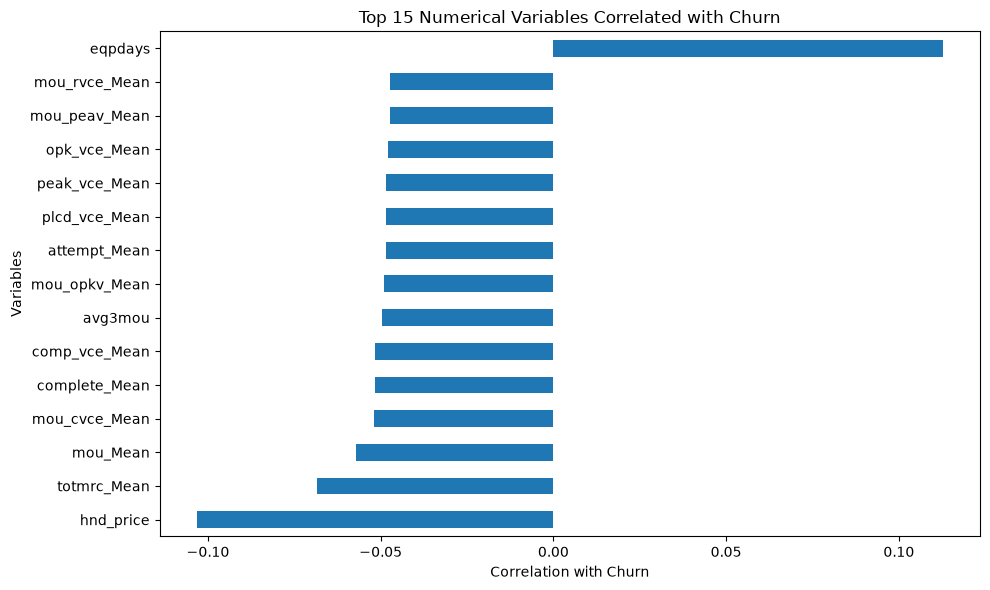

In [75]:
import matplotlib.pyplot as plt

top_correlations = churn_correlation.head(15)

plt.figure(figsize=(10, 6))

top_correlations.sort_values().plot(kind="barh")

plt.title("Top 15 Numerical Variables Correlated with Churn")
plt.xlabel("Correlation with Churn")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

In [76]:
# Divide customers into handset-age groups
data["handset_group"] = pd.cut(
    data["eqpdays"],
    bins=[-float("inf"), 180, 365, 730, float("inf")],
    labels=["0-180 days", "181-365 days", "366-730 days", "Over 730 days"]
)

# Calculate churn rate for each group
handset_churn = data.groupby(
    "handset_group",
    observed=False
)["churn"].mean() * 100

print(handset_churn)

handset_group
0-180 days       41.736236
181-365 days     46.971614
366-730 days     53.838574
Over 730 days    57.894737
Name: churn, dtype: float64


Handset age and churn

Churn rates increased with handset age, from 41.74% among customers with handsets aged 0–180 days to 57.89% among customers with handsets older than 730 days. This suggests an association between older handsets and increased customer churn.

In [77]:
data["custcare_group"] = pd.cut(
    data["custcare_Mean"],
    bins=[-float("inf"), 0, 2, 5, float("inf")],
    labels=["0 calls", "1-2 calls", "3-5 calls", "Over 5 calls"]
)

custcare_churn = data.groupby(
    "custcare_group",
    observed=False
)["churn"].mean() * 100

print(custcare_churn)

custcare_group
0 calls         51.761474
1-2 calls       48.605459
3-5 calls       45.323741
Over 5 calls    44.145370
Name: churn, dtype: float64


Customer-care calls and churn

Churn rates decreased from 51.76% among customers with zero customer-care calls to 44.15% among customers with more than five calls. This indicates a negative association between customer-care calls and churn. However, further investigation is needed to understand this relationship.


In [78]:
data["tenure_group"] = pd.cut(
    data["months"],
    bins=[0, 12, 24, 36, float("inf")],
    labels=["0-12 months", "13-24 months", "25-36 months", "Over 36 months"]
)

tenure_churn = data.groupby(
    "tenure_group",
    observed=False
)["churn"].mean() * 100

print(tenure_churn)

tenure_group
0-12 months       46.777425
13-24 months      51.779882
25-36 months      49.989487
Over 36 months    47.290380
Name: churn, dtype: float64


Customer tenure and churn

The highest churn rate (51.78%) was observed among customers with 13–24 months of tenure. Customers with more than 36 months of tenure had a lower churn rate of 47.29%. The relationship is not linear, suggesting that customer tenure alone may not explain churn.

In [79]:
# Separate the target variable
y = data["churn"]

# Remove target and customer ID from the features
X = data.drop(
    columns=["churn", "Customer_ID", "handset_group",
             "custcare_group", "tenure_group"]
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 98)
Target shape: (100000,)


In [80]:
# Identify numerical columns
numeric_columns = X.select_dtypes(include="number").columns

# Identify categorical columns
categorical_columns = X.select_dtypes(exclude="number").columns

print("Numerical columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

print("\nCategorical column names:")
print(categorical_columns.tolist())

Numerical columns: 77
Categorical columns: 21

Categorical column names:
['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


In [81]:
X = X.drop(columns=["ethnic"])

# Update the column lists
numeric_columns = X.select_dtypes(include="number").columns
categorical_columns = X.select_dtypes(exclude="number").columns

print("Numerical columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

Numerical columns: 77
Categorical columns: 20


In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Prepare numerical data
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (80000, 97)
Testing features: (20000, 97)
Training target: (80000,)
Testing target: (20000,)


In [84]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Make predictions
y_pred = logistic_model.predict(X_test)

# Calculate prediction probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.5946
Precision: 0.5909090909090909
Recall: 0.5915052461662631
F1 Score: 0.5912070182514874
ROC-AUC: 0.6280111231813792

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60     10088
           1       0.59      0.59      0.59      9912

    accuracy                           0.59     20000
   macro avg       0.59      0.59      0.59     20000
weighted avg       0.59      0.59      0.59     20000



Logistic Regression achieved an accuracy of 59.46% and a ROC-AUC of 0.628. Its predictive performance was modest, indicating that further model development and comparison are necessary.

In [86]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [87]:
# Make predictions
rf_pred = rf_model.predict(X_test)

# Calculate prediction probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 0.6194
Precision: 0.6118024499319463
Recall: 0.6348870056497176
F1 Score: 0.6231310030696109
ROC-AUC: 0.672670911635397

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.60      0.62     10088
           1       0.61      0.63      0.62      9912

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



Model comparison

Two machine-learning models were evaluated using the same test dataset. Random Forest achieved better results than Logistic Regression across all five evaluation metrics. Random Forest obtained 61.94% accuracy, 62.31% F1 score and 67.27% ROC-AUC. Therefore, Random Forest is the stronger of the two models tested so far.

In [88]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6095 3993]
 [3619 6293]]


Confusion matrix analysis

Random Forest correctly identified 6,293 churned customers and 6,095 customers who stayed. However, it missed 3,619 churners and incorrectly classified 3,993 non-churners as potential churners. The company should consider the costs of missed churners and unnecessary retention campaigns when using these predictions.

In [89]:
# Get feature importance from Random Forest
feature_importance = rf_model.named_steps["model"].feature_importances_

# Get the transformed feature names
feature_names = rf_model.named_steps["preprocessing"].get_feature_names_out()

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15).to_string(index=False))

         Feature  Importance
    num__eqpdays    0.059316
     num__months    0.044219
 num__change_mou    0.032447
   num__mou_Mean    0.024093
     num__adjrev    0.023188
     num__totrev    0.021569
num__totmrc_Mean    0.020409
     num__avgqty    0.019956
   num__totcalls    0.019769
 num__change_rev    0.019654
     num__avgrev    0.019610
    num__avg3mou    0.019458
     num__adjqty    0.019004
     num__avgmou    0.018946
     num__totmou    0.018402


Feature importance analysis

The Random Forest model identified handset age (eqpdays) as its most important feature, followed by customer tenure (months) and changes in minutes of use (change_mou). This suggests that handset age, customer tenure and usage patterns are useful indicators when predicting customer churn.

In [90]:
total_customers = len(y_test)

actual_churners = (y_test == 1).sum()

identified_churners = ((y_test == 1) & (rf_pred == 1)).sum()

missed_churners = ((y_test == 1) & (rf_pred == 0)).sum()

print("Customers tested:", total_customers)
print("Actual churners:", actual_churners)
print("Identified churners:", identified_churners)
print("Missed churners:", missed_churners)

Customers tested: 20000
Actual churners: 9912
Identified churners: 6293
Missed churners: 3619


Business opportunity

Random Forest identified 6,293 out of 9,912 actual churners in the test dataset, representing a recall of 63.49%. The company could use churn predictions to prioritise retention campaigns. However, the actual number of customers retained would depend on campaign effectiveness.

In [91]:
print("Average monthly revenue:",
      data["rev_Mean"].mean())

print("Median monthly revenue:",
      data["rev_Mean"].median())

Average monthly revenue: 58.71998484590209
Median monthly revenue: 48.195


In [92]:
identified_customers = 6293

average_revenue = data["rev_Mean"].mean()

monthly_revenue_at_risk = (
    identified_customers * average_revenue
)

print("Estimated monthly revenue at risk:",
      round(monthly_revenue_at_risk, 2))

Estimated monthly revenue at risk: 369524.86


The Random Forest model identified 6,293 customers who actually churned in the test dataset. Using the average monthly revenue of 58.72 per customer, the estimated monthly revenue associated with these customers was 369,524.86. A retention campaign could potentially protect some of this revenue, depending on its effectiveness and cost.

In [93]:
scenarios = [0.05, 0.10, 0.20]

for rate in scenarios:
    customers_saved = identified_customers * rate

    revenue_protected = (
        customers_saved * average_revenue
    )

    print(
        f"Retention rate: {rate:.0%}",
        f"| Customers saved: {customers_saved:.0f}",
        f"| Monthly revenue protected: {revenue_protected:,.2f}"
    )

Retention rate: 5% | Customers saved: 315 | Monthly revenue protected: 18,476.24
Retention rate: 10% | Customers saved: 629 | Monthly revenue protected: 36,952.49
Retention rate: 20% | Customers saved: 1259 | Monthly revenue protected: 73,904.97


Potential financial impact

Three hypothetical retention scenarios were evaluated. At a 5% retention rate, approximately 315 customers could be retained, protecting 18,476.24 in monthly revenue. At 10%, approximately 629 customers could be retained, protecting 36,952.49. At 20%, approximately 1,259 customers could be retained, protecting 73,904.97. These figures represent potential revenue protection before campaign costs, not guaranteed financial benefits.

Customer churn is a significant challenge in the global telecommunications industry. GSMA Intelligence's 2025 research found that approximately one in seven mobile users across 12 markets had switched providers within the previous year, with value for money being the leading reason. Furthermore, Simon-Kucher's 2026 Global Telecom Study found that 28% of mobile customers were considering switching providers. These findings highlight the importance of customer retention, competitive value and proactive customer engagement. Machine-learning-based churn prediction offers telecom operators an opportunity to identify customers at risk and develop targeted retention strategies.

SOURCES:
1. GSMA Intelligence (2025), The mobile churn challenge: where loyalty is lowest and four recommendations for operators.
2.Simon-Kucher (2026), Global Telecom Study 2026. 
3. Sikri, A. et al. (2024), Enhancing customer retention in telecom industry with machine learning driven churn prediction, Scientific Reports, 14, 13097.


The company should implement a targeted customer-retention strategy using the Random Forest model to identify customers at risk of churn. Priority should be given to customers with older handsets, declining usage and tenure between 13 and 24 months. Recommended interventions include personalised handset upgrade offers, suitable service bundles and proactive customer engagement. A controlled pilot should be conducted to evaluate the actual reduction in churn, revenue retained and campaign costs before wider implementation.

In [94]:
retention_strategy = {
    "Target group": "Customers with high predicted churn risk",
    "Priority 1": "Customers with older handsets",
    "Priority 2": "Customers with declining usage",
    "Actions": "Handset upgrades, loyalty rewards and personalised bundles",
    "Evaluation": "Compare churn rates using a control group"
}

print(retention_strategy)

{'Target group': 'Customers with high predicted churn risk', 'Priority 1': 'Customers with older handsets', 'Priority 2': 'Customers with declining usage', 'Actions': 'Handset upgrades, loyalty rewards and personalised bundles', 'Evaluation': 'Compare churn rates using a control group'}


In [95]:
identified_indices = X_test.index[
    (y_test == 1) & (rf_pred == 1)
]

identified_revenue = data.loc[
    identified_indices, "rev_Mean"
].sum()

print("Identified churners:", len(identified_indices))
print("Monthly revenue at risk:", round(identified_revenue, 2))

Identified churners: 6293
Monthly revenue at risk: 341431.72


In [96]:
retention_rates = [0.05, 0.10, 0.20]

for rate in retention_rates:
    revenue_protected = identified_revenue * rate
    customers_saved = round(identified_indices.size * rate)

    print(
        f"Retention rate: {rate:.0%} | "
        f"Customers saved: {customers_saved} | "
        f"Monthly revenue protected: {revenue_protected:.2f}"
    )

Retention rate: 5% | Customers saved: 315 | Monthly revenue protected: 17071.59
Retention rate: 10% | Customers saved: 629 | Monthly revenue protected: 34143.17
Retention rate: 20% | Customers saved: 1259 | Monthly revenue protected: 68286.34


In [97]:
model_limitations = [
    "Random Forest achieved a moderate ROC-AUC of 0.673.",
    "The model missed some customers who actually churned.",
    "Some customers were incorrectly flagged as likely to churn.",
    "The financial projections are hypothetical.",
    "The model identifies associations, not causes of churn.",
    "Retention campaigns must be tested before implementation."
]

for limitation in model_limitations:
    print("-", limitation)

- Random Forest achieved a moderate ROC-AUC of 0.673.
- The model missed some customers who actually churned.
- Some customers were incorrectly flagged as likely to churn.
- The financial projections are hypothetical.
- The model identifies associations, not causes of churn.
- Retention campaigns must be tested before implementation.


In [98]:
model_conclusion = """
The Random Forest model performed better than Logistic Regression
across all five evaluation metrics.

It achieved 61.94% accuracy, 63.49% recall,
62.31% F1-score and 67.27% ROC-AUC.

The model identified 6,293 actual churners in the test set.
Handset age, customer tenure and changes in usage
were among the most important predictive features.

The results suggest that machine learning can support
customer retention by identifying customers at risk.
However, the model requires further improvement
and retention strategies should be tested before implementation.
"""

print(model_conclusion)


The Random Forest model performed better than Logistic Regression
across all five evaluation metrics.

It achieved 61.94% accuracy, 63.49% recall,
62.31% F1-score and 67.27% ROC-AUC.

The model identified 6,293 actual churners in the test set.
Handset age, customer tenure and changes in usage
were among the most important predictive features.

The results suggest that machine learning can support
customer retention by identifying customers at risk.
However, the model requires further improvement
and retention strategies should be tested before implementation.



In [99]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

print(cm)

[[6095 3993]
 [3619 6293]]


In [100]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.63      0.60      0.62     10088
           1       0.61      0.63      0.62      9912

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



In [104]:
logistic_predictions = logistic_model.predict(X_test)
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       0.60      0.60      0.60     10088
           1       0.59      0.59      0.59      9912

    accuracy                           0.59     20000
   macro avg       0.59      0.59      0.59     20000
weighted avg       0.59      0.59      0.59     20000

